In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## 1. Data analysis and visualization of last 365 days

In [2]:
df365 = pd.read_csv('cleaned_KupondoleLast365days.csv')
df365

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,32.330000,%,2025-11-25 13:45:00+05:45,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,2025-11-25,13:45:00
1,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,37.049999,%,2025-11-25 17:45:00+05:45,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,2025-11-25,17:45:00
2,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,38.410000,%,2025-11-25 18:45:00+05:45,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,2025-11-25,18:45:00
3,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,38.400002,%,2025-11-25 19:45:00+05:45,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,2025-11-25,19:45:00
4,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,41.184999,%,2025-11-25 20:45:00+05:45,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,2025-11-25,20:45:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,35.049999,%,2026-01-22 17:45:00+05:45,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,2026-01-22,17:45:00
996,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,39.330001,%,2026-01-22 18:45:00+05:45,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,2026-01-22,18:45:00
997,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,41.415001,%,2026-01-22 19:45:00+05:45,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,2026-01-22,19:45:00
998,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,42.216666,%,2026-01-22 20:45:00+05:45,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,2026-01-22,20:45:00


In [3]:
df365['date'].unique()

<ArrowStringArray>
['2025-11-25', '2025-11-26', '2025-11-27', '2025-11-28', '2025-11-29',
 '2025-11-30', '2025-12-01', '2025-12-02', '2025-12-03', '2025-12-04',
 '2025-12-05', '2025-12-06', '2025-12-07', '2025-12-08', '2025-12-09',
 '2025-12-10', '2025-12-11', '2025-12-12', '2025-12-13', '2025-12-14',
 '2025-12-15', '2025-12-16', '2025-12-17', '2025-12-18', '2025-12-19',
 '2025-12-20', '2025-12-21', '2025-12-22', '2025-12-23', '2025-12-24',
 '2025-12-25', '2025-12-26', '2025-12-27', '2025-12-28', '2025-12-29',
 '2025-12-30', '2025-12-31', '2026-01-01', '2026-01-02', '2026-01-03',
 '2026-01-04', '2026-01-05', '2026-01-06', '2026-01-07', '2026-01-08',
 '2026-01-09', '2026-01-10', '2026-01-11', '2026-01-12', '2026-01-13',
 '2026-01-14', '2026-01-15', '2026-01-16', '2026-01-17', '2026-01-18',
 '2026-01-19', '2026-01-20', '2026-01-21', '2026-01-22']
Length: 59, dtype: str

In [4]:
# Group records by local calendar date and calculate the daily mean humidity.
# `value` becomes the mean relative humidity for that day.
daily_means = (
    df365.groupby(
        ["date", "location_id", "location_name", "parameter", "unit",
         "timezone", "latitude", "longitude", "owner_name", "provider"],
        as_index=False
    )
    .agg(
        value=("value", "mean"),              # daily average humidity
        observation_count=("value", "count")  # readings included that day
    )
)

# Optional: round the daily mean to two decimal places
daily_means["value"] = daily_means["value"].round(2)

In [5]:
daily_means

,date,location_id,location_name,parameter,unit,timezone,latitude,longitude,owner_name,provider,value,observation_count
0,2025-11-25,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,%,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,39.90,8
1,2025-11-26,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,%,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,39.88,18
2,2025-11-27,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,%,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,41.39,15
3,2025-11-28,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,%,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,41.18,22
4,2025-11-29,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,%,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,40.32,20
5,2025-11-30,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,%,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,42.10,17
6,2025-12-01,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,%,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,44.84,18
7,2025-12-02,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,%,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,45.43,24
8,2025-12-03,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,%,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,45.64,23
9,2025-12-04,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,%,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,41.98,18


/tmp/ipykernel_41743/2403254589.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


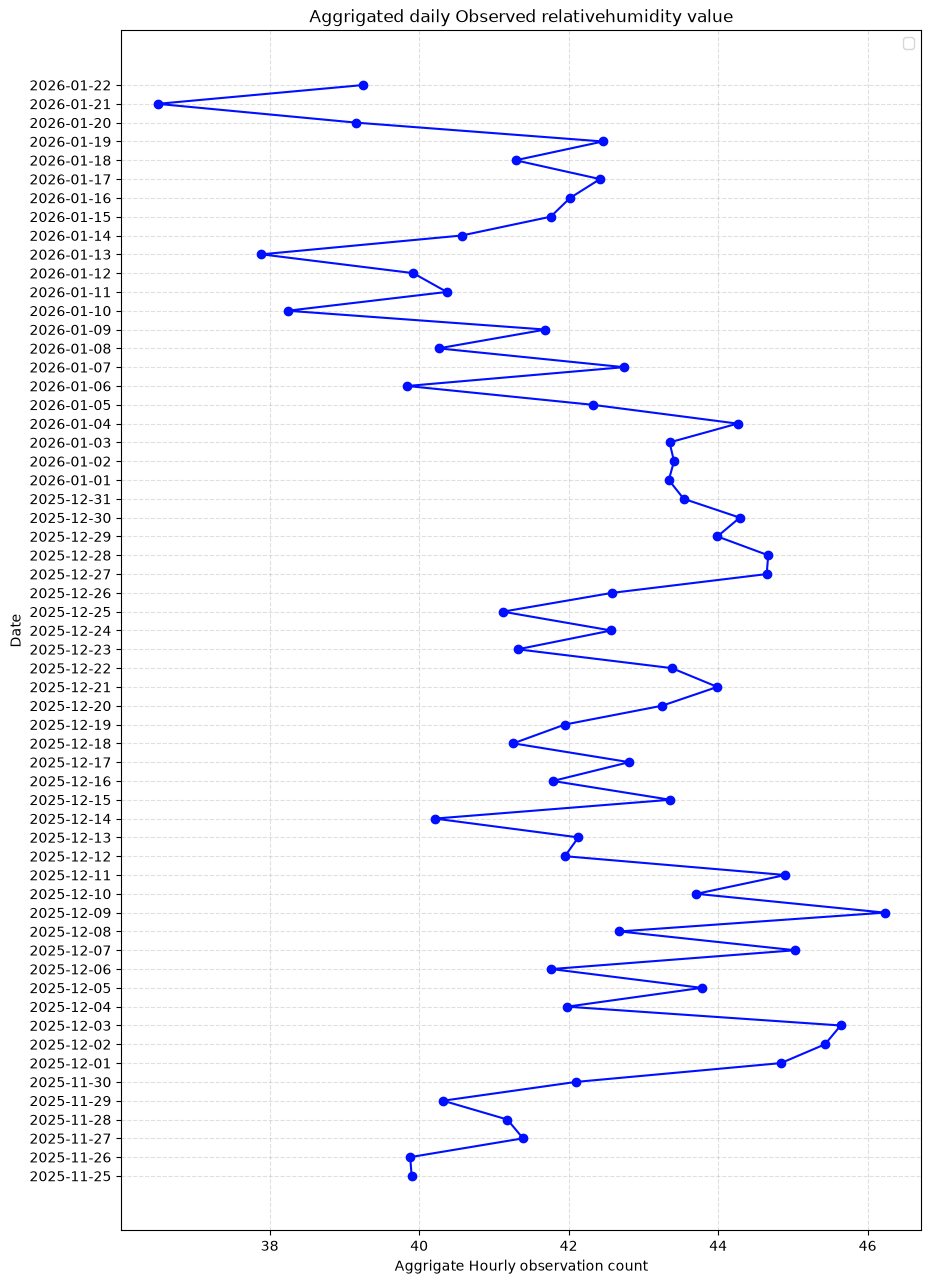

In [6]:
fig = plt.figure(figsize=(10, 15))
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.plot(daily_means['value'], daily_means['date'], color ='#000fff', marker='o')
plt.xlabel('Aggrigate Hourly observation count')
plt.ylabel('Date')
plt.title("Aggrigated daily Observed relativehumidity value")
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()

## 2. Data Analysis and Visualization of last 30 days

In [7]:
df30 = pd.read_csv('cleaned_KupondoleLast30days.csv')
df30

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,55.0,%,2026-09-12 06:45:00+05:45,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,2026-09-12,06:45:00
1,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,52.0,%,2026-09-12 07:45:00+05:45,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,2026-09-12,07:45:00
2,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,44.0,%,2026-09-12 08:45:00+05:45,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,2026-09-12,08:45:00
3,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,42.0,%,2026-09-12 09:45:00+05:45,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,2026-09-12,09:45:00
4,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,41.0,%,2026-09-12 10:45:00+05:45,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,2026-09-12,10:45:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
715,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,51.0,%,2026-10-12 01:45:00+05:45,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,2026-10-12,01:45:00
716,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,52.0,%,2026-10-12 02:45:00+05:45,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,2026-10-12,02:45:00
717,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,52.0,%,2026-10-12 03:45:00+05:45,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,2026-10-12,03:45:00
718,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,53.0,%,2026-10-12 04:45:00+05:45,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,2026-10-12,04:45:00


In [8]:
# Group records by local calendar date and calculate the daily mean humidity.
# `value` becomes the mean relative humidity for that day.
daily_means = (
    df30.groupby(
        ["date", "location_id", "location_name", "parameter", "unit",
         "timezone", "latitude", "longitude", "owner_name", "provider"],
        as_index=False
    )
    .agg(
        value=("value", "mean"),              # daily average humidity
        observation_count=("value", "count")  # readings included that day
    )
)

# Optional: round the daily mean to two decimal places
daily_means["value"] = daily_means["value"].round(2)

In [9]:
daily_means

,date,location_id,location_name,parameter,unit,timezone,latitude,longitude,owner_name,provider,value,observation_count
0,2026-09-12,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,%,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,45.83,18
1,2026-09-13,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,%,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,47.38,24
2,2026-09-14,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,%,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,47.71,24
3,2026-09-15,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,%,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,47.46,24
4,2026-09-16,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,%,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,47.62,24
5,2026-09-17,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,%,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,46.92,24
6,2026-09-18,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,%,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,47.21,24
7,2026-09-19,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,%,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,47.42,24
8,2026-09-20,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,%,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,47.54,24
9,2026-09-21,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,%,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,47.21,24


/tmp/ipykernel_41743/1124759186.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


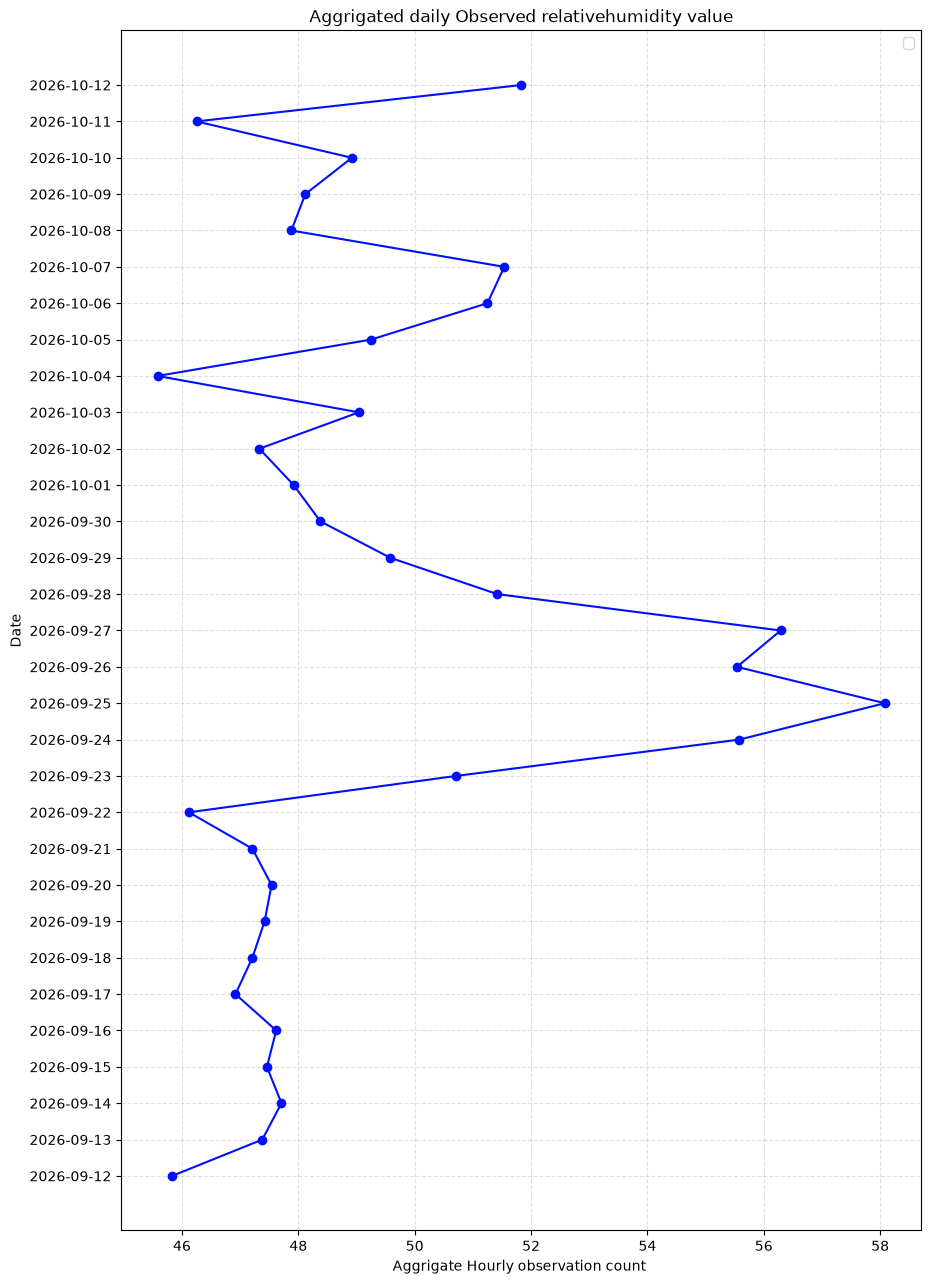

In [10]:
fig = plt.figure(figsize=(10, 15))
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.plot(daily_means['value'], daily_means['date'], color ='#000fff', marker='o')
plt.xlabel('Aggrigate Hourly observation count ')
plt.ylabel('Date')
plt.title("Aggrigated daily Observed relativehumidity value")
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()

## 3. Data analysis and Visualization of last 7 days

In [11]:
df7 = pd.read_csv('cleaned_KupondoleLast7days.csv')
df7

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,51.0,%,2026-10-05 06:45:00+05:45,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,2026-10-05,06:45:00
1,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,51.0,%,2026-10-05 07:45:00+05:45,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,2026-10-05,07:45:00
2,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,47.0,%,2026-10-05 08:45:00+05:45,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,2026-10-05,08:45:00
3,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,46.0,%,2026-10-05 09:45:00+05:45,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,2026-10-05,09:45:00
4,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,42.0,%,2026-10-05 10:45:00+05:45,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,2026-10-05,10:45:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
163,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,51.0,%,2026-10-12 01:45:00+05:45,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,2026-10-12,01:45:00
164,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,52.0,%,2026-10-12 02:45:00+05:45,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,2026-10-12,02:45:00
165,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,52.0,%,2026-10-12 03:45:00+05:45,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,2026-10-12,03:45:00
166,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,53.0,%,2026-10-12 04:45:00+05:45,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,2026-10-12,04:45:00


In [12]:
# Group records by local calendar date and calculate the daily mean humidity.
# `value` becomes the mean relative humidity for that day.
daily_means = (
    df7.groupby(
        ["date", "location_id", "location_name", "parameter", "unit",
         "timezone", "latitude", "longitude", "owner_name", "provider"],
        as_index=False
    )
    .agg(
        value=("value", "mean"),              # daily average humidity
        observation_count=("value", "count")  # readings included that day
    )
)

# Optional: round the daily mean to two decimal places
daily_means["value"] = daily_means["value"].round(2)

In [13]:
daily_means

,date,location_id,location_name,parameter,unit,timezone,latitude,longitude,owner_name,provider,value,observation_count
0,2026-10-05,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,%,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,48.83,18
1,2026-10-06,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,%,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,51.25,24
2,2026-10-07,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,%,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,51.54,24
3,2026-10-08,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,%,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,47.88,24
4,2026-10-09,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,%,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,48.12,24
5,2026-10-10,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,%,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,48.92,24
6,2026-10-11,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,%,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,46.25,24
7,2026-10-12,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,%,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,51.83,6


/tmp/ipykernel_41743/3434928225.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


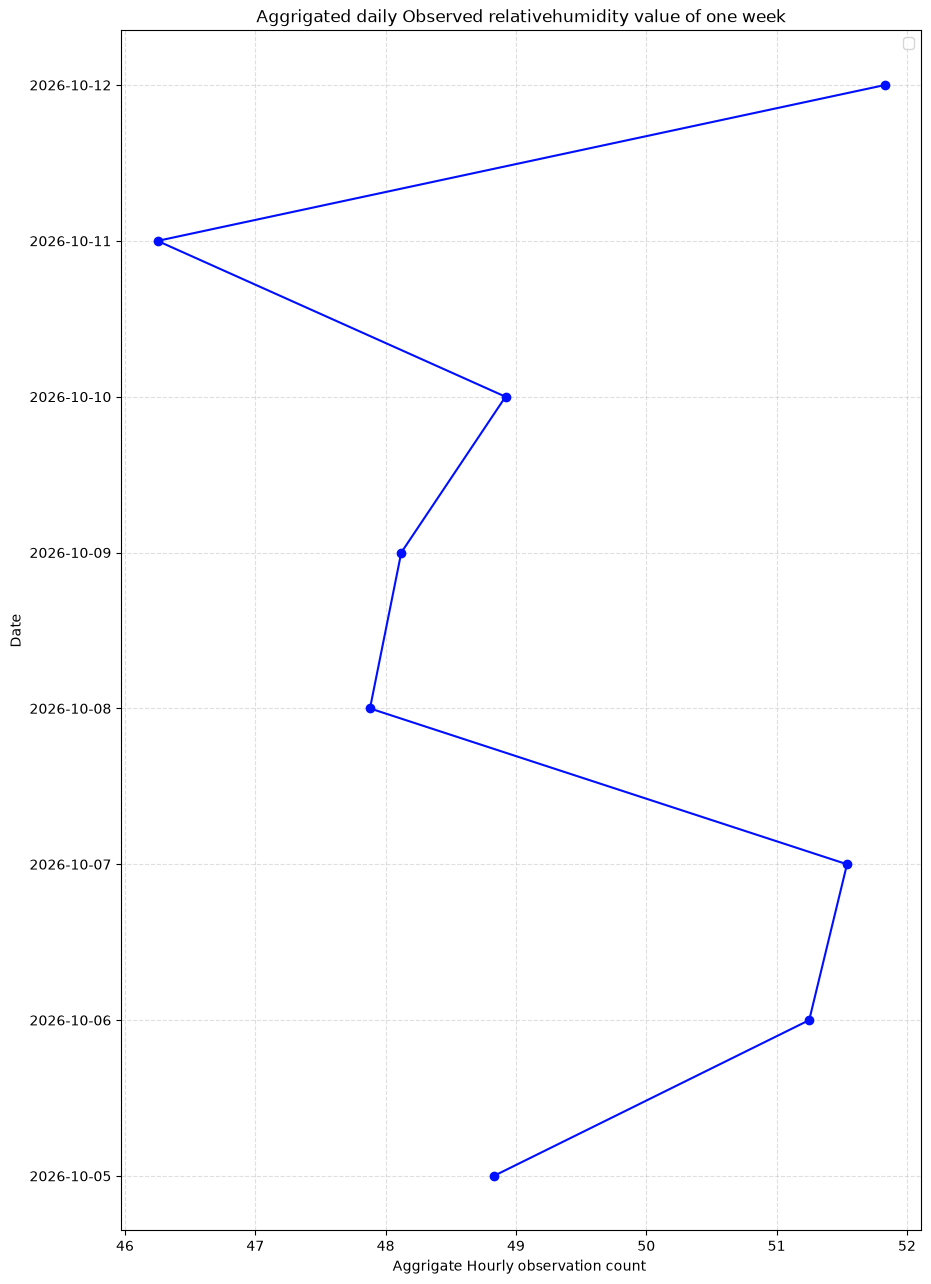

In [14]:
fig = plt.figure(figsize=(10, 15))
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.plot(daily_means['value'], daily_means['date'], color ='#000fff', marker='o')
plt.xlabel('Aggrigate Hourly observation count ')
plt.ylabel('Date')
plt.title("Aggrigated daily Observed relativehumidity value of one week")
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()

## 4. Data Analysis and Visualization of last 24 hours

In [15]:
df24 = pd.read_csv('cleaned_KupondoleLast24hours.csv')
df24

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,53.0,%,2026-10-11 06:45:00+05:45,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,2026-10-11,06:45:00
1,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,53.0,%,2026-10-11 07:45:00+05:45,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,2026-10-11,07:45:00
2,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,49.0,%,2026-10-11 08:45:00+05:45,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,2026-10-11,08:45:00
3,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,44.0,%,2026-10-11 09:45:00+05:45,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,2026-10-11,09:45:00
4,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,39.0,%,2026-10-11 10:45:00+05:45,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,2026-10-11,10:45:00
5,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,37.0,%,2026-10-11 11:45:00+05:45,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,2026-10-11,11:45:00
6,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,36.0,%,2026-10-11 12:45:00+05:45,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,2026-10-11,12:45:00
7,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,37.0,%,2026-10-11 13:45:00+05:45,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,2026-10-11,13:45:00
8,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,38.0,%,2026-10-11 14:45:00+05:45,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,2026-10-11,14:45:00
9,6141912,Kupondole (SC-40)-GD Labs,relativehumidity,40.0,%,2026-10-11 15:45:00+05:45,Asia/Kathmandu,27.689661,85.310442,Green Decision Labs and Research,AirGradient,2026-10-11,15:45:00


/tmp/ipykernel_41743/1036584907.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


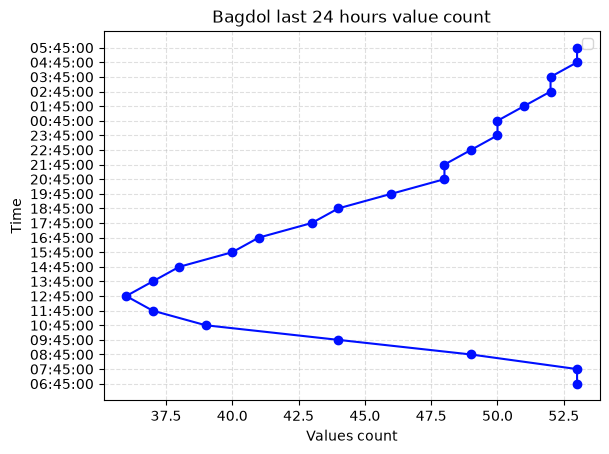

In [16]:
# Line Plot
plt.plot(df24['value'], df24['time'], color='#000fff', marker='o')
plt.xlabel('Values count')
plt.ylabel('Time')
plt.title('Bagdol last 24 hours value count')
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()